# Updated code and settings

Uses the same four-convolution architecture, 64 mel bands, FFT 512, hop 256, per-clip standardization, batch 32.

25 epochs, seed 0. Train folds 1–3, validation fold 4, held-out test fold 5. Outputs are saved in a fresh run folder.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd()
assert (ROOT / "esc50.py").exists(), "Start this notebook from the new code folder"
OUTPUT = ROOT / "outputs/jupyter-20261022-111155/new"
print("Python:", sys.executable)
print("Output:", OUTPUT)

Python: C:\Users\ryan\Desktop\work folder\new code\.venv\Scripts\python.exe
Output: C:\Users\ryan\Desktop\work folder\new code\outputs\jupyter-20261022-111155\new


In [2]:
from train import main as train_model
train_model(["--epochs", "25", "--seed", "0", "--batch-size", "32", "--feature-preset", "standardized", "--output-dir", str(OUTPUT)])

Using cached features: C:\Users\ryan\Desktop\work folder\new code\data\cache\f4e5ac761f7f1797d036.pt


Device: cuda; train: 1200; validation: 400


Epoch 01/25: train loss 3.6866, validation accuracy 14.50%


Epoch 02/25: train loss 3.2863, validation accuracy 20.75%


Epoch 03/25: train loss 3.0051, validation accuracy 23.25%


...

Epoch 22/25: train loss 1.1621, validation accuracy 56.25%


Epoch 23/25: train loss 1.1759, validation accuracy 55.50%


Epoch 24/25: train loss 1.1267, validation accuracy 60.25%


Epoch 25/25: train loss 1.0599, validation accuracy 53.75%


Best validation accuracy: 60.25% (epoch 24). Saved C:\Users\ryan\Desktop\work folder\new code\outputs\jupyter-20261022-111155\new\audionet.ckpt


In [3]:
from test import main as test_model
test_model(["--checkpoint", str(OUTPUT / "audionet.ckpt"), "--batch-size", "32"])

Using cached features: C:\Users\ryan\Desktop\work folder\new code\data\cache\f4e5ac761f7f1797d036.pt


{
  "test_fold": 5,
  "samples": 400,
  "accuracy": 0.54,
  "loss": 1.6825420665740967,
  "selected_epoch": 24,
  "validation_accuracy": 0.6025,
  "checkpoint": "C:\\Users\\ryan\\Desktop\\work folder\\new code\\outputs\\jupyter-20261022-111155\\new\\audionet.ckpt",
  "checkpoint_sha256": "fb9e64c7323b6f981063e766ca43a867d15869cb1009ead08203435fde0a8806",
  "environment": {
    "python": "3.12.11",
    "torch": "2.8.0+cu129",
    "torchaudio": "2.8.0+cu129",
    "numpy": "2.2.4",
    "device": "cuda",
    "gpu": "NVIDIA GeForce RTX 4060 Laptop GPU"
  },
  "chance_accuracy": 0.02,
  "macro_f1": 0.5107397915152256
}
Test results saved to C:\Users\ryan\Desktop\work folder\new code\outputs\jupyter-20261022-111155\new\test


,samples,accuracy,validation_accuracy,selected_epoch,macro_f1
0,400,0.54,0.6025,24,0.51074


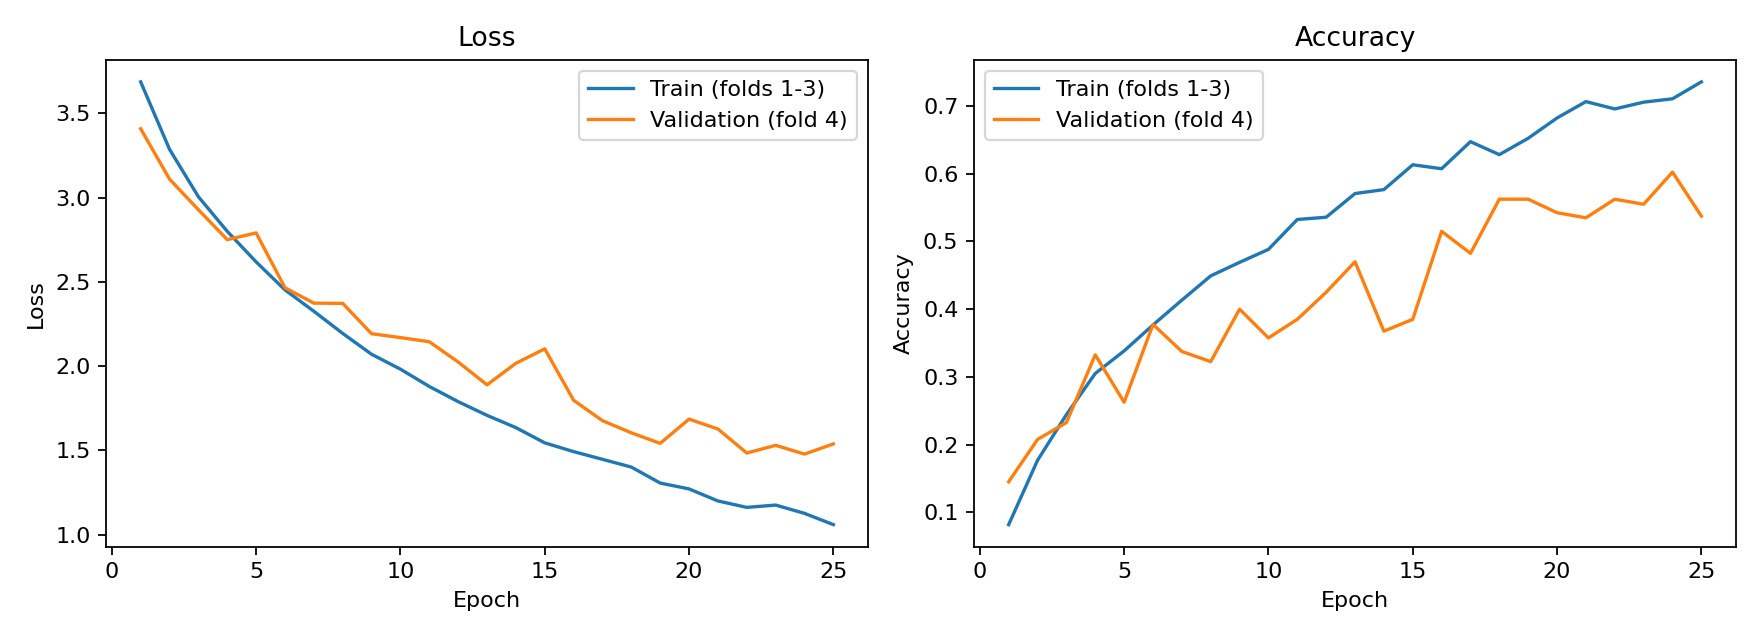

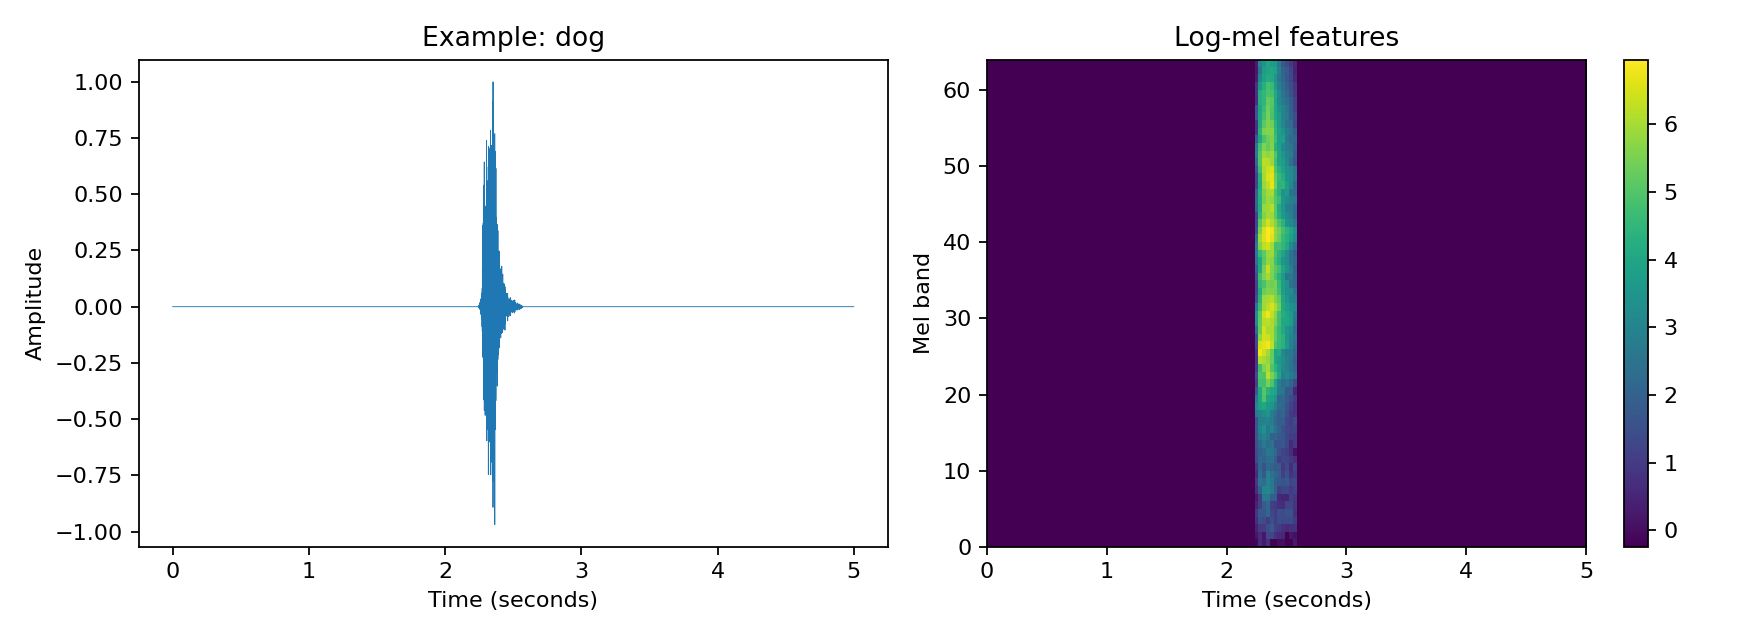

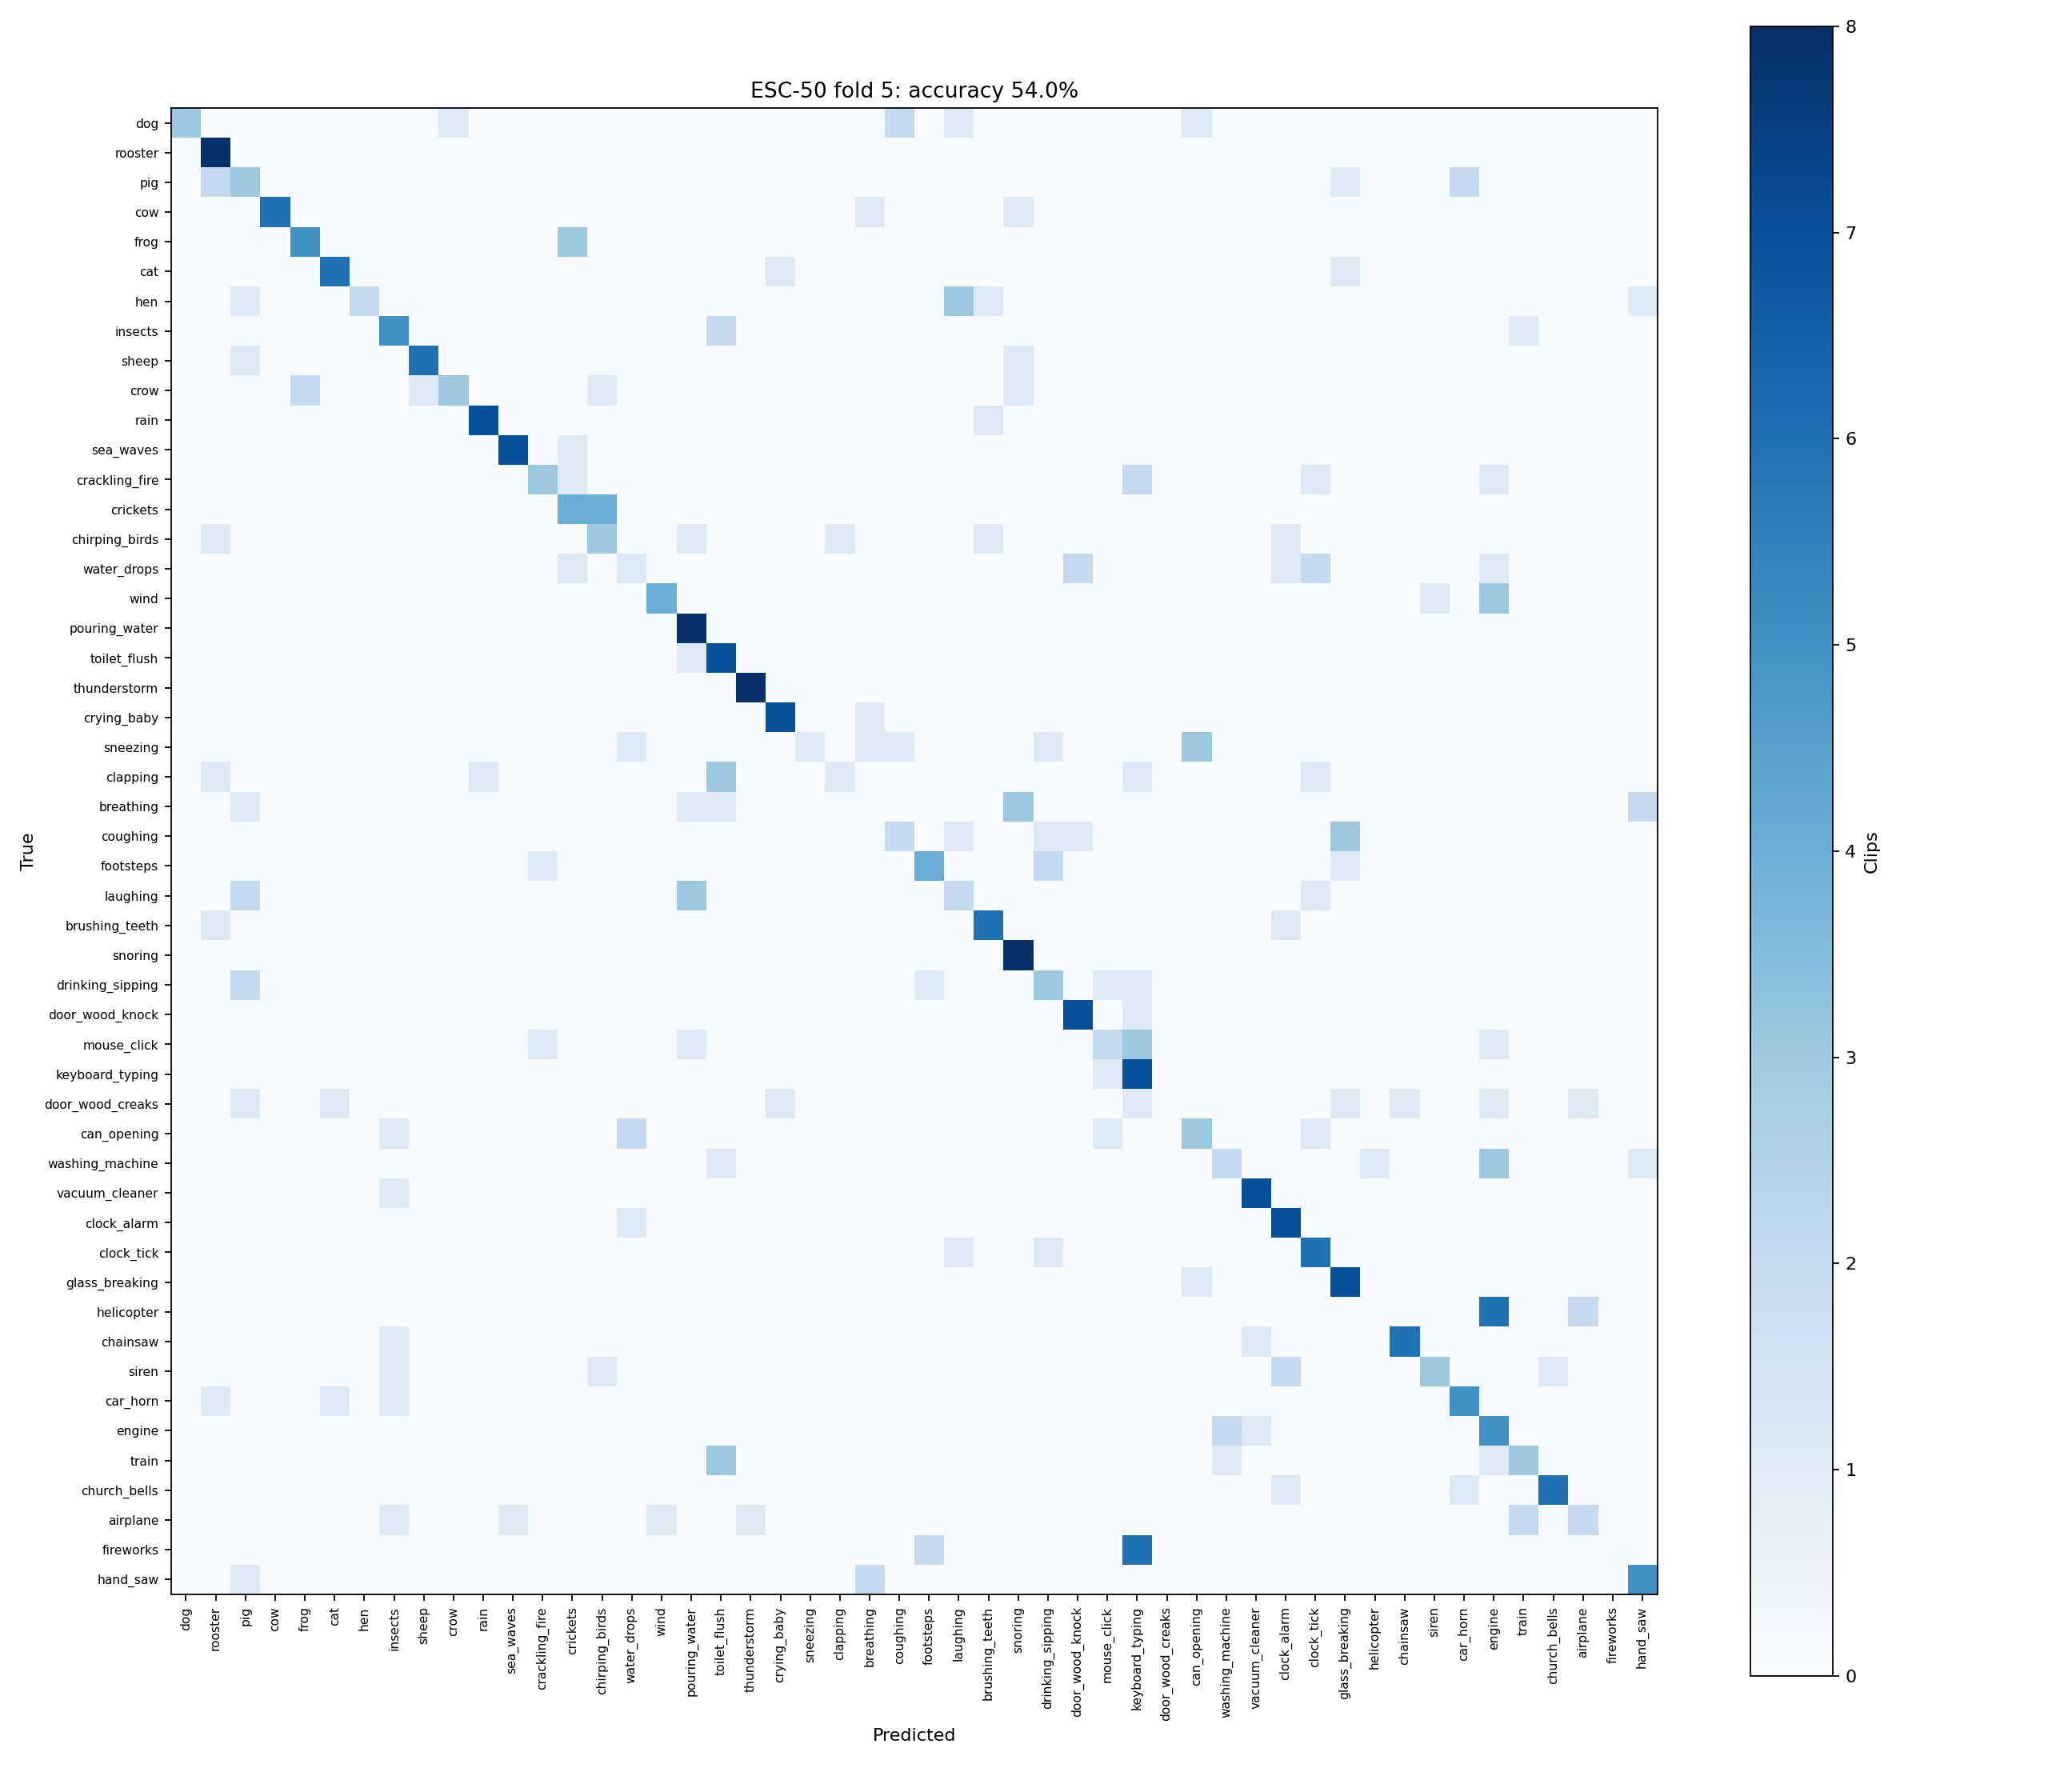

In [4]:
import json
import pandas as pd
from IPython.display import Image, display
metrics = json.loads((OUTPUT / "test" / "test_metrics.json").read_text())
display(pd.DataFrame([{k:metrics[k] for k in ["samples","accuracy","validation_accuracy","selected_epoch","macro_f1"]}]))
display(Image(filename=str(OUTPUT / "training_curves.png")))
display(Image(filename=str(OUTPUT / "audio_example.png")))
display(Image(filename=str(OUTPUT / "test" / "confusion_matrix.png")))